# 01 · A Qubit Is a Vector

**The demystification.** A qubit is a two-entry complex vector, a gate is a matrix, and measurement is the Born rule (probabilities are squared amplitudes). We build a from-scratch numpy statevector simulator and check it against PennyLane **to machine precision** — so the magic goes and the linear algebra stays.

No hardware, no account, no API key. Everything here is CPU linear algebra.

> Figures are saved to `outputs/figures/*.png` and all numbers to `outputs/data/*.json`.

In [ ]:
import sys, json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Resolve the repo root whether this runs from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

FIG = ROOT / "outputs" / "figures"
DATA = ROOT / "outputs" / "data"
FIG.mkdir(parents=True, exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)


def _ser(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, complex):
        return {"re": float(o.real), "im": float(o.imag)}
    raise TypeError(f"not JSON-serializable: {type(o)!r}")


def save_json(name, obj):
    """Save textual/numerical results to outputs/data/<name>."""
    path = DATA / name
    path.write_text(json.dumps(obj, indent=2, default=_ser))
    print("saved", path.relative_to(ROOT))


def save_fig(fig, name):
    """Save a figure as PNG to outputs/figures/<name>."""
    path = FIG / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("saved", path.relative_to(ROOT))


def amp_list(state):
    """A statevector as a JSON-friendly list of {re, im} amplitudes."""
    return [{"re": float(a.real), "im": float(a.imag)} for a in np.asarray(state)]


plt.rcParams.update({"figure.figsize": (7.0, 4.0), "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)
print("repo root:", ROOT)


repo root: /workspaces/quantum_ml_101


## A qubit is two complex numbers

The state of one qubit is $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, with $|\alpha|^2 + |\beta|^2 = 1$. In code that is a length-2 complex vector. `StateVector(1)` starts in $|0\rangle = [1, 0]$.

In [2]:
from src.sim.statevector import StateVector
from src.sim import gates

sv = StateVector(1)
print('start |0>:', sv.state)
print('H as a matrix:\n', gates.H)

start |0>: [1.+0.j 0.+0.j]
H as a matrix:
 [[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]


## A gate is a matrix; a Hadamard makes a superposition

Applying $H$ to $|0\rangle$ gives $|+\rangle = (|0\rangle + |1\rangle)/\sqrt2$: equal probability of measuring 0 or 1. Measurement is the **Born rule** — the probability of each basis state is the squared magnitude of its amplitude.

In [3]:
sv = StateVector(1).apply(gates.H, (0,))
probs = sv.probabilities()
print('amplitudes:', sv.state)
print('probabilities |0>,|1>:', probs)

# Measure the Born rule empirically: sample and count.
shots = sv.sample(5000, rng)
counts = {int(b): int((shots == b).sum()) for b in (0, 1)}
print('5000 shots:', counts)

save_json('01_plus_state.json', {
    'amplitudes': amp_list(sv.state),
    'probabilities': probs.tolist(),
    'shots': counts,
})

amplitudes: [0.70710678+0.j 0.70710678+0.j]
probabilities |0>,|1>: [0.5 0.5]
5000 shots: {0: 2545, 1: 2455}
saved outputs/data/01_plus_state.json


saved outputs/figures/01_hadamard_probabilities.png


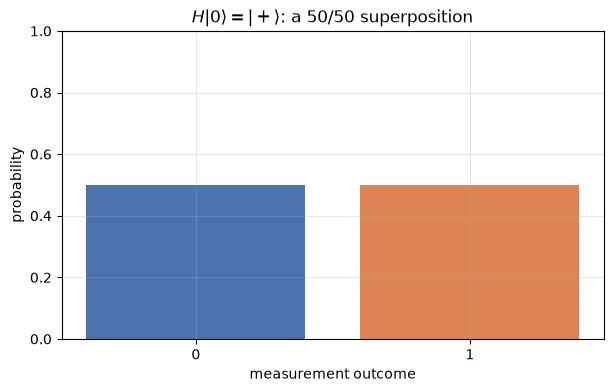

In [4]:
fig, ax = plt.subplots()
ax.bar(['0', '1'], probs, color=['#4c72b0', '#dd8452'])
ax.set_ylim(0, 1)
ax.set_ylabel('probability')
ax.set_xlabel('measurement outcome')
ax.set_title(r'$H|0\rangle = |+\rangle$: a 50/50 superposition')
save_fig(fig, '01_hadamard_probabilities.png')

## A rotation gate sweeps the probability smoothly

$R_Y(\theta)|0\rangle$ has $P(1) = \sin^2(\theta/2)$. We overlay the from-scratch simulator against that closed form — they lie on top of each other, because applying a gate really is just multiplying by its matrix.

saved outputs/figures/01_ry_sweep.png
max |sim - analytic|: 0.0
saved outputs/data/01_ry_sweep.json


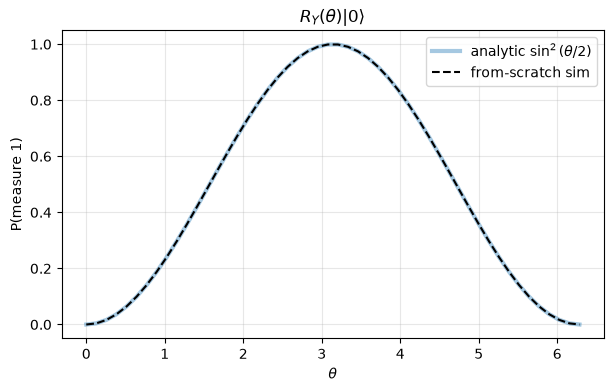

In [5]:
thetas = np.linspace(0, 2 * np.pi, 50)
p1_sim = np.array([StateVector(1).apply(gates.ry(t), (0,)).probabilities()[1] for t in thetas])
p1_exact = np.sin(thetas / 2) ** 2

fig, ax = plt.subplots()
ax.plot(thetas, p1_exact, lw=3, alpha=0.4, label=r'analytic $\sin^2(\theta/2)$')
ax.plot(thetas, p1_sim, '--', color='k', label='from-scratch sim')
ax.set_xlabel(r'$\theta$')
ax.set_ylabel('P(measure 1)')
ax.set_title(r'$R_Y(\theta)|0\rangle$')
ax.legend()
save_fig(fig, '01_ry_sweep.png')

print('max |sim - analytic|:', float(np.max(np.abs(p1_sim - p1_exact))))
save_json('01_ry_sweep.json', {
    'theta': thetas.tolist(),
    'p1_sim': p1_sim.tolist(),
    'p1_exact': p1_exact.tolist(),
    'max_abs_error': float(np.max(np.abs(p1_sim - p1_exact))),
})

## The whole point: from-scratch == PennyLane, to machine precision

If our linear algebra is right, our final statevector equals PennyLane's for the same circuit, down to floating-point noise (~1e-15). This is the asserted claim the test suite also checks.

In [6]:
from src.sim.vs_pennylane import max_abs_diff

circuits = {
    'H on |0>': (1, [('H', (0,), ())]),
    'RY(0.7)': (1, [('RY', (0,), (0.7,))]),
    'H then RY(1.1)': (1, [('H', (0,), ()), ('RY', (0,), (1.1,))]),
}
report = {name: max_abs_diff(n, ops) for name, (n, ops) in circuits.items()}
for name, diff in report.items():
    print(f'{name:>16}:  max|diff| = {diff:.2e}')

save_json('01_validation.json', report)
assert max(report.values()) < 1e-12, 'from-scratch simulator disagrees with PennyLane!'
print('\nPASS: a quantum computation on one qubit is just linear algebra.')

        H on |0>:  max|diff| = 0.00e+00
         RY(0.7):  max|diff| = 0.00e+00
  H then RY(1.1):  max|diff| = 0.00e+00
saved outputs/data/01_validation.json

PASS: a quantum computation on one qubit is just linear algebra.


## Takeaways

- A qubit is a 2-vector of complex amplitudes; $N$ qubits are a $2^N$ vector.
- A gate is a unitary matrix; measurement is the Born rule, $P = |\text{amp}|^2$.
- A few dozen lines of numpy reproduce PennyLane exactly.

Next: **02 — Circuits and Entanglement**, where the $2^N$ cost becomes a wall.